In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

DATA_DIR = "data"
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = "f1_macro"
LABELS = {0: "low", 1: "medium", 2: "high"}

---
## 1. Data cleaning & labeling schema

| Class | Rule |
|---|---|
| `low` (0) | quality ≤ 5 |
| `medium` (1) | quality = 6 |
| `high` (2) | quality ≥ 7 |

In [3]:
red = pd.read_csv(f"{DATA_DIR}/winequality-red.csv", sep=";").assign(wine_type="red")
white = pd.read_csv(f"{DATA_DIR}/winequality-white.csv", sep=";").assign(wine_type="white")
print("raw shapes  -> red:", red.shape, "| white:", white.shape)

dups = {"red": red.duplicated().sum(), "white": white.duplicated().sum()}
print("duplicates  ->", dups)

df = pd.concat([red.drop_duplicates(), white.drop_duplicates()], ignore_index=True)
print("clean shape ->", df.shape)
df.info()

raw shapes  -> red: (1599, 13) | white: (4898, 13)
duplicates  -> {'red': np.int64(240), 'white': np.int64(937)}
clean shape -> (5320, 13)
<class 'pandas.DataFrame'>
RangeIndex: 5320 entries, 0 to 5319
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5320 non-null   float64
 1   volatile acidity      5320 non-null   float64
 2   citric acid           5320 non-null   float64
 3   residual sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free sulfur dioxide   5320 non-null   float64
 6   total sulfur dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   int64  
 12  wine_type             5320 non-null   str    


In [4]:
num_cols = df.select_dtypes("number").columns
display(df[num_cols].describe().T[["min", "mean", "max"]])

,min,mean,max
fixed acidity,3.80000,7.215179,15.90000
volatile acidity,0.08000,0.344130,1.58000
citric acid,0.00000,0.318494,1.66000
residual sugar,0.60000,5.048477,65.80000
chlorides,0.00900,0.056690,0.61100
free sulfur dioxide,1.00000,30.036654,289.00000
total sulfur dioxide,6.00000,114.109023,440.00000
density,0.98711,0.994535,1.03898
pH,2.72000,3.224664,4.01000
sulphates,0.22000,0.533357,2.00000


In [5]:
df["label"] = np.select([df["quality"] <= 5, df["quality"] == 6], [0, 1], default=2)

dist = (df.groupby(["wine_type", "label"]).size().unstack(fill_value=0)
          .rename(columns=LABELS))
dist.loc["total"] = dist.sum()
display(dist)
print((df["label"].value_counts(normalize=True).sort_index().rename(LABELS) * 100).round(1).astype(str) + "%")

label,low,medium,high
wine_type,,,
red,640,535,184
white,1348,1788,825
total,1988,2323,1009


label
low       37.4%
medium    43.7%
high      19.0%
Name: proportion, dtype: str


In [6]:
assert df.isna().sum().sum() == 0, "Missing values found"
assert df.duplicated().sum() == 0, "Duplicates still present"
assert (df[num_cols] >= 0).all().all(), "Negative physicochemical values found"
assert df["quality"].between(0, 10).all(), "Quality outside 0-10"
assert set(df["label"].unique()) == {0, 1, 2}, "Unexpected label values"
min_share = df["label"].value_counts(normalize=True).min()
assert min_share >= 0.10, f"Smallest class is only {min_share:.1%}"
print(f"Step 1 passed: {len(df)} rows, smallest class = {min_share:.1%}")

Step 1 passed: 5320 rows, smallest class = 19.0%


---
## 2. Data preprocessing & feature engineering

**Input features**

| # | Feature | Unit / meaning | Expected effect on quality |
|---|---|---|---|
| 1 | fixed acidity | tartaric acid, g/dm³ | weak |
| 2 | volatile acidity | acetic acid, g/dm³ (vinegar taste) | negative |
| 3 | citric acid | g/dm³ (freshness) | weak positive |
| 4 | residual sugar | g/dm³ after fermentation | weak |
| 5 | chlorides | salt, g/dm³ | negative |
| 6 | free sulfur dioxide | mg/dm³ (antimicrobial) | weak |
| 7 | total sulfur dioxide | mg/dm³ | negative |
| 8 | density | g/cm³ (tracks sugar and alcohol) | negative |
| 9 | pH | acidity scale | weak |
| 10 | sulphates | potassium sulphate, g/dm³ | positive |
| 11 | alcohol | % vol | strongest positive |
| 12 | **is_red** | engineered: 1 = red, 0 = white | lets one model handle both wine types |

`wine_type` replaced by the `is_red`

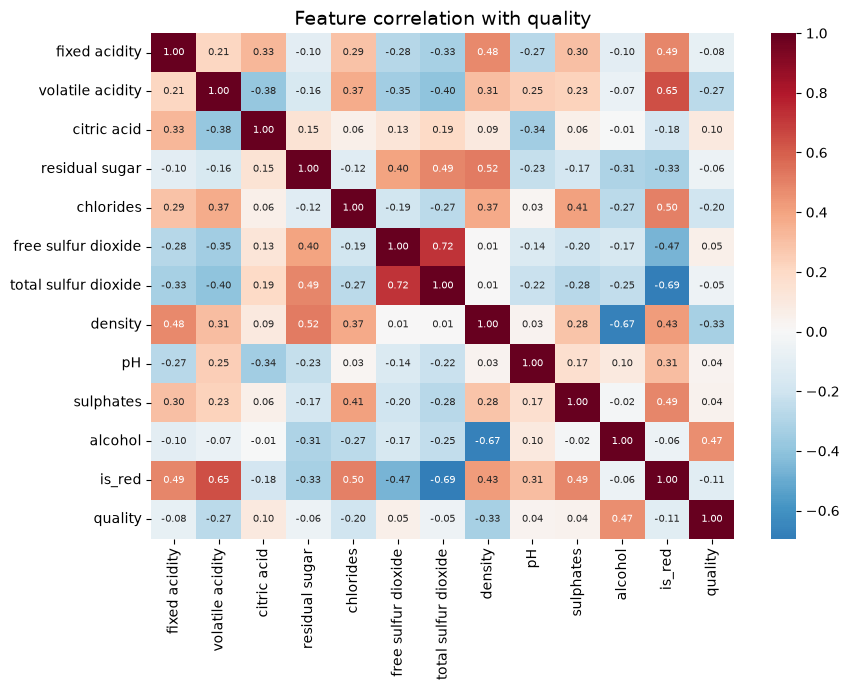

alcohol                 0.469
density                -0.326
volatile acidity       -0.265
chlorides              -0.202
is_red                 -0.115
citric acid             0.098
fixed acidity          -0.080
residual sugar         -0.057
free sulfur dioxide     0.054
total sulfur dioxide   -0.050
sulphates               0.042
pH                      0.040
Name: quality, dtype: float64


In [7]:
BASE_FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar",
                 "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
                 "pH", "sulphates", "alcohol", "is_red"]

df["is_red"] = (df["wine_type"] == "red").astype(int)

corr = df[BASE_FEATURES + ["quality"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Feature correlation with quality", fontsize=14)
plt.tight_layout(); plt.show()

print(corr["quality"].drop("quality").sort_values(key=abs, ascending=False).round(3))

In [8]:
X = df[BASE_FEATURES]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (4256, 12) | test: (1064, 12)


In [9]:
def add_engineered(frame):
    out = frame.copy()
    out["total_acidity"] = out["fixed acidity"] + out["volatile acidity"] + out["citric acid"]
    out["free_so2_ratio"] = out["free sulfur dioxide"] / out["total sulfur dioxide"]
    return out

rf_probe = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)
base_cv = cross_val_score(rf_probe, X_train, y_train, cv=CV, scoring=SCORING).mean()
eng_cv = cross_val_score(rf_probe, add_engineered(X_train), y_train, cv=CV, scoring=SCORING).mean()
gain = eng_cv - base_cv
print(f"CV macro-F1  base: {base_cv:.4f} | + engineered: {eng_cv:.4f} | gain: {gain:+.4f}")

USE_ENGINEERED = gain >= 0.01
if USE_ENGINEERED:
    X_train, X_test = add_engineered(X_train), add_engineered(X_test)
FEATURES = list(X_train.columns)
print("Engineered features kept:", USE_ENGINEERED)
print("Final features (%d):" % len(FEATURES), FEATURES)

CV macro-F1  base: 0.6141 | + engineered: 0.6028 | gain: -0.0113
Engineered features kept: False
Final features (12): ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'is_red']


In [10]:
assert not {"quality", "label", "wine_type"} & set(FEATURES), "Leakage: target-related column in features"
assert X_train.index.intersection(X_test.index).empty, "Train/test overlap"
share_gap = (y_train.value_counts(normalize=True) - y_test.value_counts(normalize=True)).abs().max()
assert share_gap < 0.01, f"Split not stratified (gap {share_gap:.3f})"
for name, m in [("train", X_train), ("test", X_test)]:
    assert np.isfinite(m.to_numpy()).all(), f"NaN/inf in {name} features"
print(f"Checkpoint 2 passed: {len(FEATURES)} features, max class-share gap = {share_gap:.4f}")

Checkpoint 2 passed: 12 features, max class-share gap = 0.0007


---
## 3. Training & hyperparameter tuning

| Hyperparameter | Values | What it controls |
|---|---|---|
| `n_estimators` | 200, 300, 500 | number of trees (more = more stable, slower) |
| `max_depth` | None, 10, 20, 30 | tree depth limit (lower = less overfitting) |
| `min_samples_leaf` | 1, 2, 4 | minimum samples per leaf (higher = smoother) |
| `max_features` | sqrt, log2, 0.5 | features tried per split (the "random" in random forest) |
| `class_weight` | None, balanced | upweights the smaller `high` class |

In [11]:
dummy_cv = cross_val_score(DummyClassifier(strategy="most_frequent"), X_train, y_train, cv=CV, scoring=SCORING)
default_cv = cross_val_score(RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
                             X_train, y_train, cv=CV, scoring=SCORING)
print(f"Dummy      CV macro-F1: {dummy_cv.mean():.4f}")
print(f"Default RF CV macro-F1: {default_cv.mean():.4f} ± {default_cv.std():.4f}")

Dummy      CV macro-F1: 0.2026
Default RF CV macro-F1: 0.6054 ± 0.0109


In [12]:
param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced"],
}
search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=param_dist, n_iter=30, scoring=SCORING, cv=CV,
    random_state=RANDOM_STATE, n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)

best_model = search.best_estimator_
best_idx = search.best_index_
best_cv, best_std = search.best_score_, search.cv_results_["std_test_score"][best_idx]
print("Best params:", search.best_params_)
print(f"Best CV macro-F1: {best_cv:.4f} ± {best_std:.4f}")

top = (pd.DataFrame(search.cv_results_)
         .sort_values("rank_test_score")
         [["params", "mean_test_score", "std_test_score", "mean_train_score"]].head(5))
display(top)

/Users/rayhanatmadja/Development/supervised-randomforest/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/rayhanatmadja/Development/supervised-randomforest/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/rayhanatmadja/Development/supervised-randomforest/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current 

Best params: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced'}
Best CV macro-F1: 0.6141 ± 0.0148


,params,mean_test_score,std_test_score,mean_train_score
5,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",0.614090,0.014814,0.979333
0,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",0.614002,0.014916,0.979333
13,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.613291,0.012713,1.000000
15,"{'n_estimators': 500, 'min_samples_leaf': 2, '...",0.613126,0.013281,0.980057
12,"{'n_estimators': 300, 'min_samples_leaf': 1, '...",0.611289,0.014216,0.999951


In [13]:
assert best_cv - dummy_cv.mean() >= 0.20, "Tuned model barely beats the dummy baseline"
assert best_cv >= default_cv.mean() - 0.01, "Tuned model is worse than default RF"
assert best_std < 0.05, f"Unstable CV scores (std {best_std:.3f})"
print(f"Checkpoint 3 passed: tuned {best_cv:.4f} vs default {default_cv.mean():.4f} vs dummy {dummy_cv.mean():.4f}")

Checkpoint 3 passed: tuned 0.6141 vs default 0.6054 vs dummy 0.2026


---
## 3. Evaluation & inference

Test accuracy : 0.5855
Test macro-F1 : 0.5868  (CV estimate was 0.6141)

              precision    recall  f1-score   support

         low      0.638     0.705     0.670       397
      medium      0.559     0.447     0.497       465
        high      0.534     0.668     0.593       202

    accuracy                          0.586      1064
   macro avg      0.577     0.607     0.587      1064
weighted avg      0.584     0.586     0.580      1064



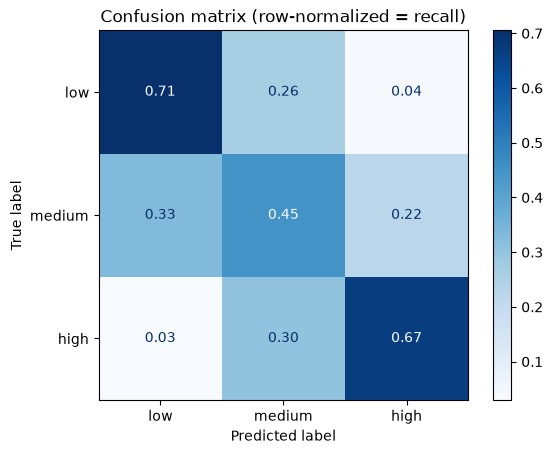

In [14]:
y_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
print(f"Test accuracy : {test_acc:.4f}")
print(f"Test macro-F1 : {test_f1:.4f}  (CV estimate was {best_cv:.4f})\n")
print(classification_report(y_test, y_pred, target_names=list(LABELS.values()), digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=list(LABELS.values()),
                                        cmap="Blues", normalize="true", values_format=".2f")
plt.title("Confusion matrix (row-normalized = recall)"); plt.show()

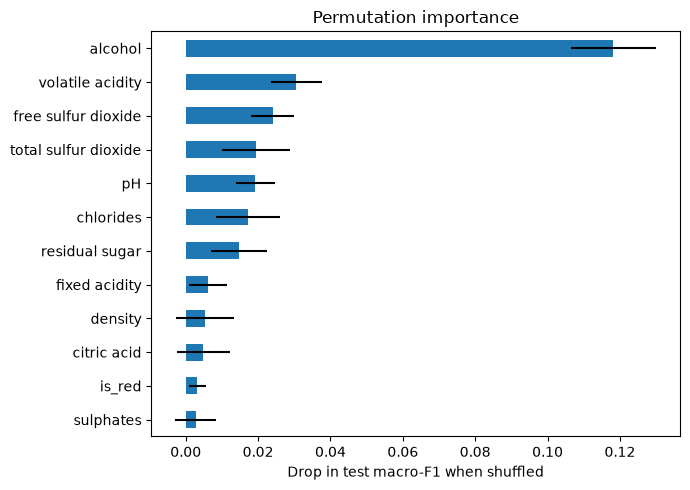

alcohol                 0.1182
volatile acidity        0.0306
free sulfur dioxide     0.0240
total sulfur dioxide    0.0193
pH                      0.0192
dtype: float64


In [15]:
perm = permutation_importance(best_model, X_test, y_test, scoring=SCORING,
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 5), xerr=pd.Series(perm.importances_std, index=FEATURES)[imp.index])
plt.xlabel("Drop in test macro-F1 when shuffled"); plt.title("Permutation importance")
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(4).head(5))

In [ ]:
MODEL_PATH = "rf_wine_quality.joblib"
joblib.dump({"model": best_model, "features": FEATURES, "labels": LABELS,
             "use_engineered": USE_ENGINEERED}, MODEL_PATH)

def predict_wine(sample: dict, bundle_path=MODEL_PATH):
    bundle = joblib.load(bundle_path)
    row = pd.DataFrame([sample])
    row["is_red"] = int(sample.get("wine_type", "red") == "red") if "is_red" not in sample else sample["is_red"]
    if bundle["use_engineered"]:
        row = add_engineered(row)
    missing = set(bundle["features"]) - set(row.columns)
    if missing:
        raise ValueError(f"Missing features: {sorted(missing)}")
    row = row[bundle["features"]]
    proba = bundle["model"].predict_proba(row)[0]
    return {"label": bundle["labels"][int(proba.argmax())],
            "probabilities": {bundle["labels"][i]: round(float(p), 3) for i, p in enumerate(proba)}}

for wt in ["red", "white"]:
    idx = df.loc[X_test.index].query("wine_type == @wt").index[0]
    sample = df.loc[idx, BASE_FEATURES[:-1]].to_dict() | {"wine_type": wt}
    print(f"{wt:5s} | true: {LABELS[df.loc[idx, 'label']]:6s} | predicted: {predict_wine(sample)}")

red   | true: low    | predicted: {'label': 'low', 'probabilities': {'low': 0.765, 'medium': 0.205, 'high': 0.03}}
white | true: high   | predicted: {'label': 'high', 'probabilities': {'low': 0.018, 'medium': 0.068, 'high': 0.915}}


In [17]:
from sklearn.metrics import recall_score
reloaded = joblib.load(MODEL_PATH)["model"]
per_class_recall = recall_score(y_test, y_pred, average=None)

assert abs(test_f1 - best_cv) <= 0.05, f"Test score deviates from CV by {test_f1 - best_cv:+.3f}"
assert test_f1 > dummy_cv.mean(), "Test score does not beat the dummy baseline"
assert per_class_recall.min() >= 0.40, f"A class is mostly missed: recall {per_class_recall.round(2)}"
assert (reloaded.predict(X_test) == y_pred).all(), "Saved model does not reproduce predictions"
print(f"Checkpoint 4 passed: test macro-F1 {test_f1:.4f} (CV {best_cv:.4f}), "
      f"per-class recall {dict(zip(LABELS.values(), per_class_recall.round(3)))}")

Checkpoint 4 passed: test macro-F1 0.5868 (CV 0.6141), per-class recall {'low': np.float64(0.705), 'medium': np.float64(0.447), 'high': np.float64(0.668)}
